In [1]:
import glob
import numpy as np 
import matplotlib.pyplot as plt 
import metpy.calc as mpc 
import xarray as xr 
from metpy.units import units 
import cartopy.crs as ccrs 
import cartopy 

In [2]:
import pandas as pd

In [3]:
monthly_avg = '/lustre/storeB/project/fou/hi/foccus/datasets/norkystv3_averages/monthly_avg/*.nc'
dss = xr.open_mfdataset(monthly_avg, combine = 'nested', concat_dim = 'time')
dss['time'] = pd.date_range('2024-01', periods=12, freq='MS')

In [4]:
ds = dss.mean(dim = 'time')

In [5]:
ds

<xarray.Dataset> Size: 214MB
Dimensions:           (Y: 1148, X: 2747)
Coordinates:
    s_rho             float64 8B -0.004904
  * X                 (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * Y                 (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.168e+05 9.176e+05
    s_w               float64 8B 0.0
    lon               (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    lat               (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
Data variables: (12/18)
    Uwind_eastward    (Y, X) float32 13MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    Vwind_northward   (Y, X) float32 13MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    zeta              (Y, X) float32 13MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    ubar_eastward     (Y, X) float32 13MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    vbar_northward    (Y, X) float32 13MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    u_eastward        (Y, X) float32 13MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    ...                ...
    hc                float64 8B 100.0
    Cs_r              float64 8B -1.673e-05
    Cs_w              float64 8B 0.0
    h                 (Y, X) float32 13MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    projection_stere  float64 8B -2.147e+09
    depth             float64 8B -2.147e+09

In [5]:
temp = ds['temperature']
u = ds['u_eastward']
v = ds['v_northward']
lon = ds['lon']
lat = ds['lat']

In [6]:
temperature = temp * units.celsius 
u_speed = u * units('m/s')
v_speed = v * units('m/s')
frontogenesis_yearly_avg = mpc.frontogenesis(temperature, u_speed, v_speed, longitude = lon, latitude = lat)

/tmp/ipykernel_3902385/1681361915.py:4: UserWarning: More than one vertical coordinate present for variable  "temperature".
  frontogenesis_yearly_avg = mpc.frontogenesis(temperature, u_speed, v_speed, longitude = lon, latitude = lat)


In [7]:
frontogenesis_yearly_avg

<xarray.DataArray (Y: 1148, X: 2747)> Size: 25MB
<Quantity([[            nan             nan             nan ... -7.64131308e-12
  -7.26358488e-11 -2.93987242e-11]
 [            nan             nan             nan ...  6.51398553e-12
  -8.53239390e-12 -4.18119194e-11]
 [            nan             nan             nan ... -4.47451993e-12
  -2.45258416e-12 -9.37286563e-11]
 ...
 [            nan             nan             nan ...  4.57239800e-10
  -5.96695822e-11  8.54695553e-11]
 [            nan             nan             nan ...  2.42056944e-10
  -4.85695903e-11  7.64611304e-11]
 [            nan             nan             nan ... -1.05239784e-10
  -1.58743466e-10  3.20811969e-11]], 'kelvin / meter / second')>
Coordinates:
    s_rho    float64 8B -0.004904
  * X        (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * Y        (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.16e+05 9.168e+05 9.176e+05
    s_w      float64 8B 0.0
    lon      (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    lat      (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>

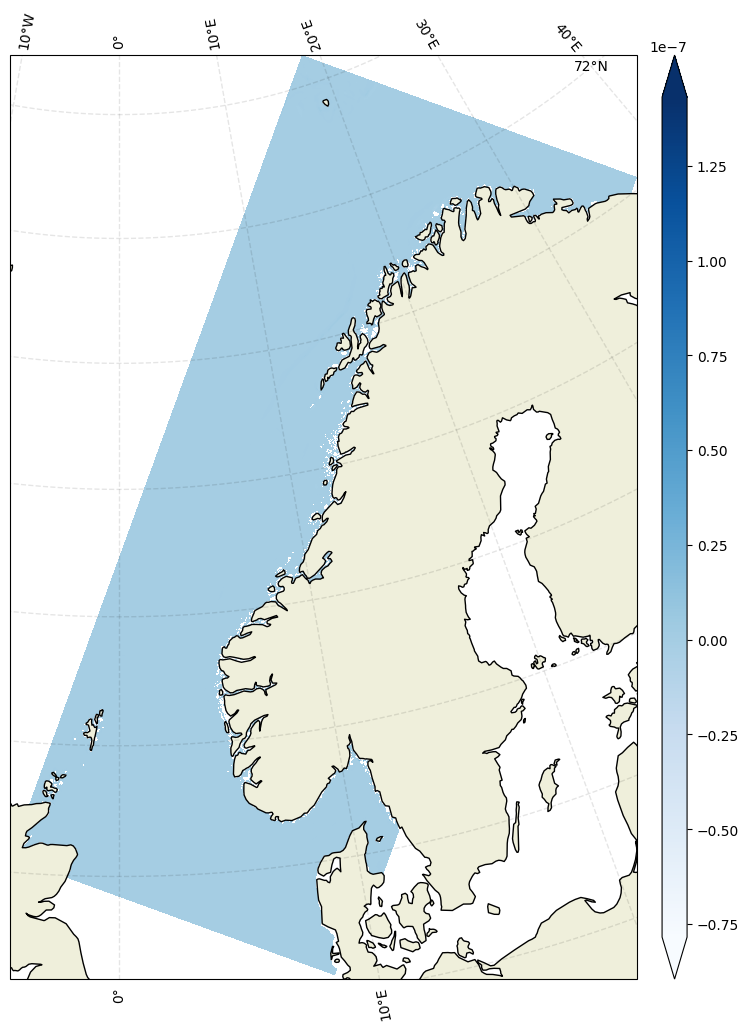

In [8]:
fig, ax = plt.subplots(figsize = (10,12), subplot_kw={'projection' : ccrs.NorthPolarStereo()})
im = ax.pcolormesh(ds.lon, ds.lat, frontogenesis_yearly_avg[:,:], cmap = 'Blues', transform = ccrs.PlateCarree())
cax = fig.add_axes([ax.get_position().x1+0.025, ax.get_position().y0, 0.025, ax.get_position().height])
cbar = fig.colorbar(im, ax=ax, cax = cax, extend = 'both')
gl = ax.gridlines(crs = ccrs.PlateCarree(), draw_labels = True, linewidth = 1, color = 'black', alpha = 0.1, linestyle = '--')
gl.xlabels_top = False 
gl.ylabels_right = False 
ax.add_feature(cartopy.feature.LAND, zorder = 1, edgecolor = 'black')

In [9]:
dss.time.values

array(['2024-01-01T00:00:00.000000000', '2024-02-01T00:00:00.000000000',
       '2024-03-01T00:00:00.000000000', '2024-04-01T00:00:00.000000000',
       '2024-05-01T00:00:00.000000000', '2024-06-01T00:00:00.000000000',
       '2024-07-01T00:00:00.000000000', '2024-08-01T00:00:00.000000000',
       '2024-09-01T00:00:00.000000000', '2024-10-01T00:00:00.000000000',
       '2024-11-01T00:00:00.000000000', '2024-12-01T00:00:00.000000000'],
      dtype='datetime64[ns]')

In [10]:
month_length = dss.time.dt.days_in_month
month_length

<xarray.DataArray 'days_in_month' (time: 12)> Size: 96B
array([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
Coordinates:
    s_rho    float64 8B -0.004904
    s_w      float64 8B 0.0
  * time     (time) datetime64[ns] 96B 2024-01-01 2024-02-01 ... 2024-12-01

In [11]:
weights = (month_length.groupby('time.season') / month_length.groupby('time.season').sum())
ds_weighted_by_season = (dss * weights).groupby('time.season').sum(dim = 'time')

In [12]:
ds_weighted_by_season.lon

<xarray.DataArray 'lon' (Y: 1148, X: 2747)> Size: 25MB
dask.array<where, shape=(1148, 2747), dtype=float64, chunksize=(1148, 2747), chunktype=numpy.ndarray>
Coordinates:
  * X        (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * Y        (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.16e+05 9.168e+05 9.176e+05
    lon      (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    lat      (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
Attributes:
    units:          degree_east
    long_name:      longitude
    standard_name:  longitude
    field:          lon, scalar
    _metpy_axis:    longitude

In [13]:
temperature_DJF = ds_weighted_by_season.temperature[0,:,:]
temperature_JJA = ds_weighted_by_season.temperature[1,:,:]
temperature_SON = ds_weighted_by_season.temperature[2,:,:]  
temperature_MAM = ds_weighted_by_season.temperature[3,:,:]
longitude = ds_weighted_by_season.lon.stack()
latitude = ds_weighted_by_season.lat.stack()
u_DJF = ds_weighted_by_season.u_eastward[0,:,:]
u_JJA = ds_weighted_by_season.u_eastward[1,:,:]
u_SON = ds_weighted_by_season.u_eastward[2,:,:]
u_MAM = ds_weighted_by_season.u_eastward[3,:,:]
v_DJF = ds_weighted_by_season.v_northward[0,:,:]
v_JJA = ds_weighted_by_season.v_northward[1,:,:]
v_SON = ds_weighted_by_season.v_northward[2,:,:]
v_MAM = ds_weighted_by_season.v_northward[3,:,:]

temp_unitDJF = temperature_DJF * units.celsius
temp_unitJJA = temperature_JJA * units.celsius
temp_unitSON = temperature_SON * units.celsius
temp_unitMAM = temperature_MAM * units.celsius

u_DJF_unit = u_DJF * units('m/s')
u_JJA_unit = u_JJA * units('m/s')
u_SON_unit = u_SON * units('m/s')
u_MAM_unit = u_MAM * units('m/s')
v_DJF_unit = v_DJF * units('m/s')
v_JJA_unit = v_JJA * units('m/s')
v_SON_unit = v_SON * units('m/s')
v_MAM_unit = v_MAM * units('m/s')

In [14]:
u_DJF_unit

<xarray.DataArray 'u_eastward' (Y: 1148, X: 2747)> Size: 25MB
<Quantity(dask.array<mul, shape=(1148, 2747), dtype=float64, chunksize=(1148, 2747), chunktype=numpy.ndarray>, 'meter / second')>
Coordinates:
  * X        (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * Y        (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.16e+05 9.168e+05 9.176e+05
    lon      (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    lat      (Y, X) float64 25MB dask.array<chunksize=(1148, 2747), meta=np.ndarray>
    season   <U3 12B 'DJF'

In [15]:
print(longitude.shape)  # Skal være (n,) eller (1, n)

(1148, 2747)


In [16]:
frontogenesisDJF = mpc.frontogenesis(temp_unitDJF, u_DJF_unit, v_DJF_unit, longitude = longitude, latitude = latitude)
frontogenesisJJA = mpc.frontogenesis(temp_unitJJA, u_JJA_unit, v_JJA_unit, longitude = longitude, latitude = latitude)
frontogenesisSON = mpc.frontogenesis(temp_unitSON, u_SON_unit, v_SON_unit, longitude = longitude, latitude = latitude)
frontogenesisMAM = mpc.frontogenesis(temp_unitMAM, u_MAM_unit, v_MAM_unit, longitude = longitude, latitude = latitude) 

In [25]:
frontogenesisDJF.values.min()
#frontogenesisDJF.values.mean()

np.float64(-6.686220288994205e-06)

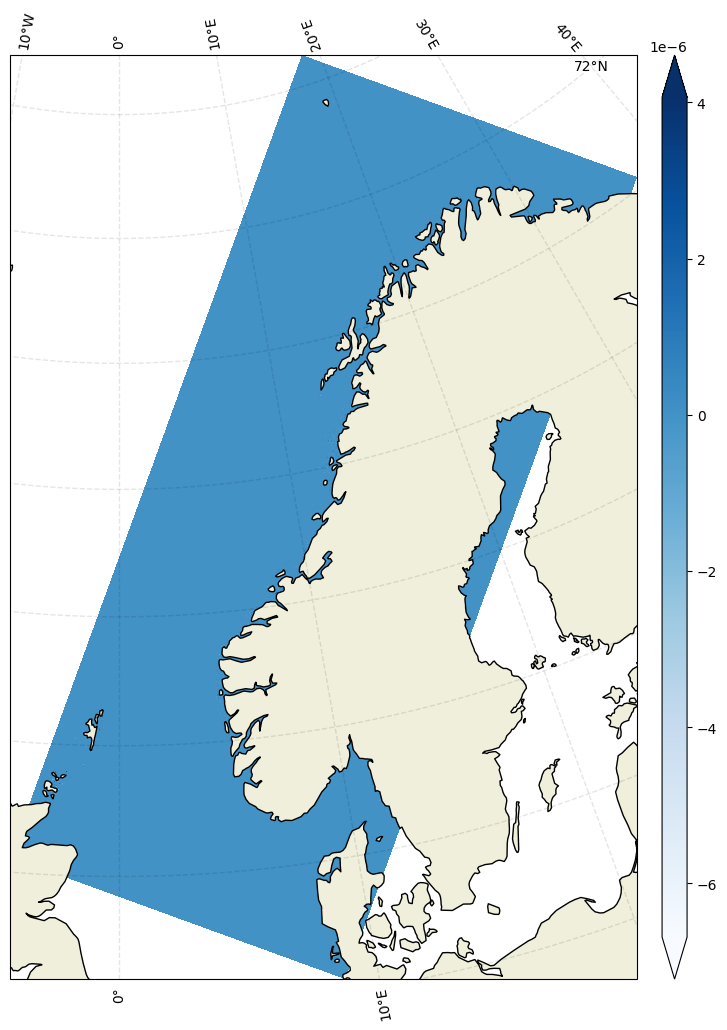

In [17]:
fig, ax = plt.subplots(figsize = (10,12), subplot_kw={'projection' : ccrs.NorthPolarStereo()})
im = ax.pcolormesh(ds.lon, ds.lat, frontogenesisDJF[:,:], cmap = 'Blues', transform = ccrs.PlateCarree())
cax = fig.add_axes([ax.get_position().x1+0.025, ax.get_position().y0, 0.025, ax.get_position().height])
cbar = fig.colorbar(im, ax=ax, cax = cax, extend = 'both')
gl = ax.gridlines(crs = ccrs.PlateCarree(), draw_labels = True, linewidth = 1, color = 'black', alpha = 0.1, linestyle = '--')
gl.xlabels_top = False 
gl.ylabels_right = False 
ax.add_feature(cartopy.feature.LAND, zorder = 1, edgecolor = 'black')